# 05b · Model selection and validation
**Owner:** P5 (Prediction Model & Monsoon Lift) · **Extends:** T25, T26

**Question.** Why were Ridge, Random Forest and XGBoost chosen, and how do we know the winner is really the best?

**Approach.**
1. Measure the traits of the data, using only days before the first forecast, and let them point to model families.
2. Compare the existing models with stronger baselines and new candidates (11 in total).
3. Test on the **last year** (365 days: both monsoons and both hot seasons) with a rolling backtest in which every
   forecast uses only earlier days; models are refitted and re-tuned every 7 days.
4. Score the generator's own expected value as a reference: the best any model could do, since the orders are synthetic.
5. Test whether the differences are bigger than luck, and apply a decision rule fixed before the results were seen.

**Decision rule.** A candidate replaces Ridge only if its MAE is lower, its Holm-adjusted Diebold-Mariano p-value is
below 0.05, **and** its 95% block-bootstrap interval for the MAE difference lies below zero. Otherwise Ridge stays.

In [1]:
import sys, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
import model_selection as ms, plotstyle, predict
plotstyle.apply()
C = plotstyle.C

ORDERS_CSV = ROOT / "data/raw/daily_orders.csv"
WEATHER_CSV = ROOT / "data/raw/weather.csv"
RESULTS = ROOT / "results"; RESULTS.mkdir(exist_ok=True)

## 1. Data profile: which traits point to which models
Measured only on the rows before the first forecast, so the test period does not influence the choice of models.

In [2]:
full = predict.load_model_frame(WEATHER_CSV, ORDERS_CSV)
X = predict.make_features(full)
y = full["order_count"].loc[X.index]
first = ms.first_test_day(X, initial=len(X) - ms.TEST_DAYS)
Xpre, ypre = X[X.index < first], y[y.index < first]
print(f"Training rows before the first forecast: {len(Xpre)}. Test days: {(X.index >= first).sum()}, "
      f"{first.date()} to {X.index.max().date()}")
profile = ms.profile_data(Xpre, ypre)
profile.round(4).to_csv(RESULTS / "selection_data_profile.csv", index=False)
pd.set_option("display.max_colwidth", None)
profile.round(4)

Training rows before the first forecast: 725. Test days: 365, 2025-09-25 to 2026-09-24


,trait,value,reading,points_to
0,Training days,725.0000,Sample available before the first forecast,Sets how complex a model can be
1,Days per feature,34.5238,Enough days per feature,Any family
2,Variance / mean,29.1131,Counts spread wider than Poisson,Negative Binomial
3,Autocorrelation at 1 day,0.3212,Yesterday carries information about today,"Lag features, SARIMAX"
4,Autocorrelation at 7 days,0.5410,Weekly memory,"SARIMAX, seasonal baselines"
5,ADF p-value,0.0001,Below 0.05 rejects a unit root,Decides differencing in SARIMAX
6,KPSS p-value,0.1000,Below 0.05 rejects stationarity,Decides differencing in SARIMAX
7,RESET p-value,0.0141,Linear form is missing something,"Tree models: RF, XGBoost, Extra Trees"
8,Rain x weekend F-test p-value,0.0000,Rain works differently on weekdays and weekends,Linear models need the interaction term; trees can find it alone


## 2. Rolling backtest on the last year
Every model is refitted and re-tuned every 7 days using only earlier days. The generator's expected value is added as
a reference row; it is not a candidate and is not part of the significance tests.

In [3]:
preds = ms.rolling_backtest(X, y, ms.make_models(), first)
preds[ms.REFERENCE] = ms.generator_expected(ORDERS_CSV, preds.index)
y_test = y.loc[preds.index]
table = ms.compare_to_incumbent(y_test, preds, ypre)
preds.round(2).to_csv(RESULTS / "selection_backtest_forecasts.csv")
table.astype(float).round(3).to_csv(RESULTS / "selection_metrics.csv")
table.astype(float).round(3)

,R2,MAE,MSE,RMSE,MAPE_%,bias,MASE,delta_MAE,dm_stat,dm_p,dm_p_holm,ci_low,ci_high
Generator expected value,0.925,14.768,349.803,18.703,9.346,0.778,0.307,-0.311,NaN,NaN,NaN,NaN,NaN
SARIMAX,0.921,14.991,369.250,19.216,9.475,0.463,0.312,-0.088,-0.795,0.427,1.000,-0.317,0.138
Negative Binomial,0.923,14.994,362.037,19.027,9.447,0.960,0.312,-0.085,-0.730,0.466,1.000,-0.278,0.096
Poisson,0.922,15.029,365.318,19.113,9.467,1.085,0.313,-0.050,-0.382,0.702,1.000,-0.262,0.155
Extra Trees,0.920,15.079,376.490,19.403,9.517,0.646,0.314,-0.000,-0.001,0.999,1.000,-0.409,0.426
Ridge,0.920,15.079,374.849,19.361,9.503,0.870,0.314,0.000,NaN,NaN,NaN,NaN,NaN
ElasticNet,0.920,15.099,375.565,19.379,9.517,0.883,0.314,0.020,0.811,0.418,1.000,-0.026,0.072
Random Forest,0.915,15.602,396.865,19.921,9.854,0.695,0.325,0.523,2.175,0.030,0.182,0.024,1.025
XGBoost,0.911,16.056,418.341,20.453,10.094,0.793,0.334,0.977,3.188,0.002,0.011,0.373,1.614
Weekday mean,0.518,37.977,2257.634,47.515,23.865,1.998,0.790,22.898,14.601,0.000,0.000,19.959,26.282


In [4]:
verdict = ms.decide(table)
print("Winner:", verdict["winner"]); print(verdict["reason"])

Winner: Ridge
No candidate cleared all three conditions, so Ridge stays.


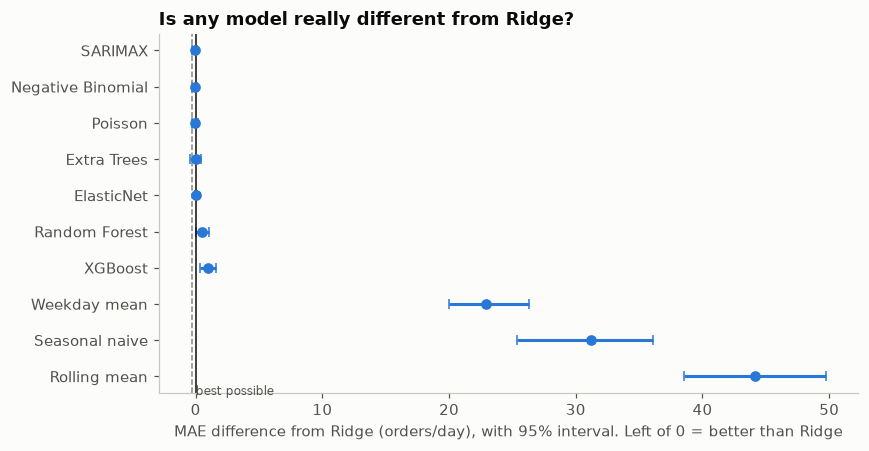

In [5]:
others = table.drop(index=[ms.INCUMBENT, ms.REFERENCE]).astype(float).sort_values("delta_MAE")
fig, ax = plt.subplots(figsize=(8, 4.2))
pos = range(len(others))
ax.errorbar(others["delta_MAE"], pos, xerr=[others["delta_MAE"] - others["ci_low"], others["ci_high"] - others["delta_MAE"]],
            fmt="o", color=C["blue"], capsize=3)
ax.axvline(0, color=C["ink"], lw=1)
ref = float(table.loc[ms.REFERENCE, "delta_MAE"])
ax.axvline(ref, color=C["gray"], lw=1, ls="--")
ax.text(ref, len(others) - 0.4, " best possible", color=C["ink2"], fontsize=8, va="bottom")
ax.set_yticks(list(pos)); ax.set_yticklabels(others.index); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("MAE difference from Ridge (orders/day), with 95% interval. Left of 0 = better than Ridge")
ax.set_title("Is any model really different from Ridge?")
fig.tight_layout(); fig.savefig(RESULTS / "fig20_mae_difference_vs_ridge.png", dpi=150); plt.show()

### Where each model does well or badly
Rain lifts weekday orders and lowers weekend orders, so errors are split by weather and by day type together.

In [6]:
ctx = full.loc[preds.index]
day_type = np.where(ctx["dow"].isin([4, 5, 6]), "Fri-Sun", "Mon-Thu")
cell = pd.Series([f"{r} {d}" for r, d in zip(ctx["regime"], day_type)], index=ctx.index)
segments = ms.segment_table(y_test, preds, cell).loc[table.index]
segments.round(2).to_csv(RESULTS / "selection_metrics_by_segment.csv")
print("Days per cell:", segments.attrs.get("days") or ms.segment_table(y_test, preds, cell).attrs["days"])
segments.round(2)

Days per cell: {'normal Mon-Thu': 99, 'normal Fri-Sun': 73, 'rainy Mon-Thu': 59, 'hot Mon-Thu': 51, 'rainy Fri-Sun': 50, 'hot Fri-Sun': 33}


,MAE hot Fri-Sun,MAE hot Mon-Thu,MAE normal Fri-Sun,MAE normal Mon-Thu,MAE rainy Fri-Sun,MAE rainy Mon-Thu
Generator expected value,20.28,11.42,20.14,11.29,11.81,16.27
SARIMAX,20.92,11.78,20.74,11.20,11.28,16.84
Negative Binomial,20.70,11.57,20.72,11.22,11.50,16.96
Poisson,20.75,11.69,20.77,11.14,11.61,17.04
Extra Trees,21.32,11.29,20.66,11.23,11.32,17.60
Ridge,21.14,11.97,20.76,11.21,11.31,17.03
ElasticNet,21.17,12.04,20.79,11.14,11.40,17.08
Random Forest,21.47,11.17,21.05,11.39,12.55,19.05
XGBoost,21.72,11.98,22.89,11.28,12.78,18.76
Weekday mean,55.38,14.94,37.22,18.04,82.51,44.81


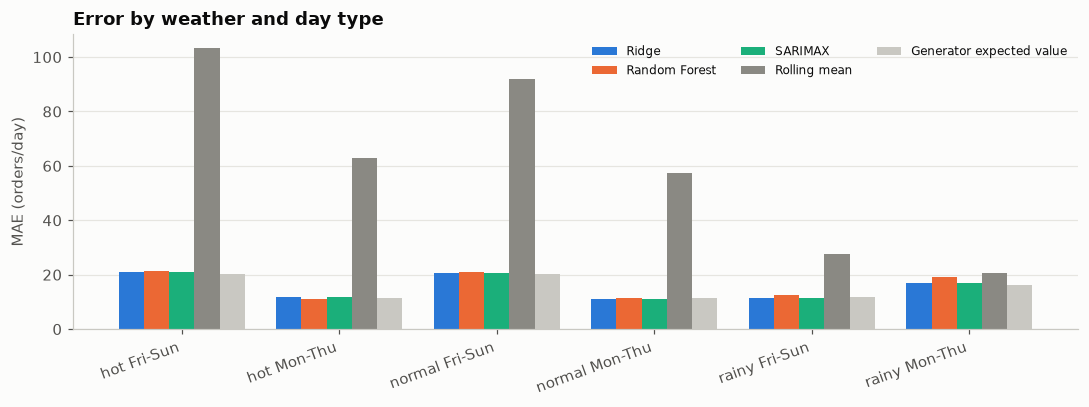

In [7]:
show = [ms.INCUMBENT, "Random Forest", "SARIMAX", "Rolling mean", ms.REFERENCE]
cols = [c for c in segments.columns if c.endswith(("Mon-Thu", "Fri-Sun"))]
fig, ax = plt.subplots(figsize=(10, 3.8))
pos = np.arange(len(cols)); w = 0.16
colors = [C["blue"], C["orange"], C["aqua"], C["gray"], C["light"]]
for k, (m, col) in enumerate(zip(show, colors)):
    ax.bar(pos + (k - 2) * w, segments.loc[m, cols], w, color=col, label=m)
ax.set_xticks(pos); ax.set_xticklabels([c.replace("MAE ", "") for c in cols], rotation=20, ha="right")
ax.set_ylabel("MAE (orders/day)"); ax.set_title("Error by weather and day type"); ax.legend(ncol=3, fontsize=8)
fig.tight_layout(); fig.savefig(RESULTS / "fig22_error_by_segment.png", dpi=150); plt.show()

## 3. How much does weather help?
The models above use the **actual** weather of the predicted day, which a live system would not know in advance, so
their accuracy is a best case. This run removes same-day weather, the rain x weekend term and monsoon phase. Baselines
ignore weather and do not change.

In [8]:
kept = ms.no_weather_columns(X)
print("Features kept:", ", ".join(kept))
preds_nw = ms.rolling_backtest(X[kept], y, ms.make_models(), first).loc[preds.index]
candidates = [m for m in preds.columns if m != ms.REFERENCE]
rows = {}
for m in candidates:
    e_w, e_nw = y_test - preds[m], y_test - preds_nw[m]
    stat, p = ms.diebold_mariano(e_nw, e_w) if not np.allclose(e_w, e_nw) else (0.0, 1.0)
    low, high = ms.block_bootstrap_ci(e_nw.abs() - e_w.abs())
    rows[m] = {"MAE with weather": e_w.abs().mean(), "MAE without weather": e_nw.abs().mean(),
               "weather saves": (e_nw.abs() - e_w.abs()).mean(), "dm_p": p, "ci_low": low, "ci_high": high}
weather_effect = pd.DataFrame(rows).T
weather_effect["dm_p_holm"] = ms.holm(weather_effect["dm_p"].tolist())
weather_effect = weather_effect.loc[[m for m in table.index if m in candidates]]
weather_effect.round(3).to_csv(RESULTS / "selection_weather_effect.csv")
weather_effect.round(3)

Features kept: lag1, lag7, roll7, is_fri_sun, is_festival, dow_0, dow_1, dow_2, dow_3, dow_4, dow_5, dow_6


,MAE with weather,MAE without weather,weather saves,dm_p,ci_low,ci_high,dm_p_holm
SARIMAX,14.991,37.156,22.165,0.0,18.830,25.648,0.0
Negative Binomial,14.994,37.115,22.121,0.0,19.154,25.448,0.0
Poisson,15.029,36.992,21.963,0.0,18.999,25.276,0.0
Extra Trees,15.079,34.349,19.271,0.0,16.011,23.217,0.0
Ridge,15.079,37.440,22.361,0.0,19.273,25.694,0.0
ElasticNet,15.099,37.419,22.320,0.0,19.240,25.629,0.0
Random Forest,15.602,34.138,18.536,0.0,15.315,22.365,0.0
XGBoost,16.056,34.178,18.123,0.0,15.068,21.815,0.0
Weekday mean,37.977,37.977,0.000,1.0,0.000,0.000,1.0
Seasonal naive,46.304,46.304,0.000,1.0,0.000,0.000,1.0


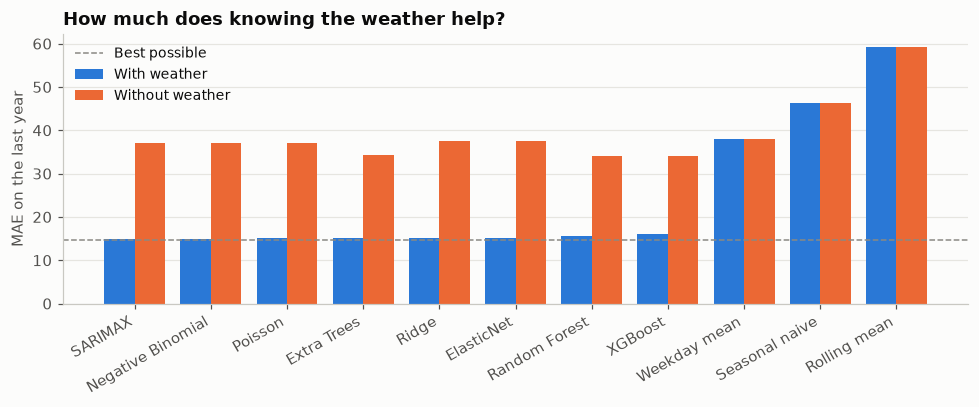

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
pos = np.arange(len(weather_effect)); w = 0.4
ax.bar(pos - w / 2, weather_effect["MAE with weather"], w, color=C["blue"], label="With weather")
ax.bar(pos + w / 2, weather_effect["MAE without weather"], w, color=C["orange"], label="Without weather")
ax.axhline(float(table.loc[ms.REFERENCE, "MAE"]), color=C["gray"], ls="--", lw=1, label="Best possible")
ax.set_xticks(pos); ax.set_xticklabels(weather_effect.index, rotation=30, ha="right")
ax.set_ylabel("MAE on the last year"); ax.set_title("How much does knowing the weather help?"); ax.legend()
fig.tight_layout(); fig.savefig(RESULTS / "fig21_weather_effect.png", dpi=150); plt.show()

## 4. Limits of this evidence
- **Synthetic orders.** All days come from the evidence-based generator (`docs/generator.md`), so the comparison shows
  which model recovers its documented rules best; the generator's expected value marks the ceiling.
- **No day-to-day memory.** The generator draws each day independently, so lag features can only learn the weekly
  pattern. Real restaurant data usually has memory, which would favour lag-based models more than here.
- **Best-case weather.** Models use observed weather, not a forecast.
- **One test year.** 2025-09-25 to 2026-09-24. Rainy-weekend and hot cells have fewer days; their counts are printed above.
- **Candidates were not blind.** Ridge was fixed as the incumbent before this run, from the earlier 56-day holdout
  (05_model), whose days fall inside this test year.